# <img style="float: left; padding-right: 10px; width: 100px" src="https://raw.githubusercontent.com/sbildea/SEED/main/imagini/unitbv_mie.png"> <center>Știința Explorării și Exploatării Datelor - SEED1</center>


##    <center>Extra 5: Exerciții de regresie logistică</center>
**Universitatea Transilvania**<br>
**SIIPA, Semestrul I**<br>
**Instructor:** Conf. dr. Teodor &Scedil;tefan B&icirc;ldea<br>
**Contact:** teodor.bildea@unitbv.ro<br>


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sbildea/SEED/blob/main/cursuri/05-clasificare/extra-05-exercitii-regresie-logistica.ipynb)

In [ ]:
# Configurare curs SEED: rulați această celulă prima.
# În Colab descarcă materialele cursului și instalează pachetele lipsă (aprox. un minut).
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/SEED"):
        !git clone -q --depth 1 https://github.com/sbildea/SEED.git /content/SEED
        !pip install -q -r /content/SEED/requirements.txt
    %cd /content/SEED/cursuri/05-clasificare
sys.path.insert(0, os.path.abspath("../.."))

# Exercițiul 1

Pentru setul de date **Heart.csv** folosit și la cursul 8 construiți modelul de regresrie logistică cu predictor `Chol` și variabilă target `AHD` folosind clasa **LogisticRegression** din modulul **sklearn.linear_model**. 

Răspundeți la următoarele cerințe:
1. Scrieți modelul de regresie logistică pentru funcția de mai sus.
2. Interpretati $\widehat{\beta}_{1}$.
3. Estimați probabilitatea de boală cardiacă pentru cineva cu Chol≈200.

In [41]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import os
print(os.getcwd() )
df = pd.read_csv('./date/Heart-v2.csv')
df

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,typical,110,264,0,0,132,0,1.2,2,0.0,reversable,Yes
299,68,1,asymptomatic,144,193,1,0,141,0,3.4,2,2.0,reversable,Yes
300,57,1,asymptomatic,130,131,0,0,115,1,1.2,2,1.0,reversable,Yes
301,57,0,nontypical,130,236,0,2,174,0,0.0,2,1.0,normal,Yes


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Age        303 non-null    int64  
 1   Sex        303 non-null    int64  
 2   ChestPain  303 non-null    object 
 3   RestBP     303 non-null    int64  
 4   Chol       303 non-null    int64  
 5   Fbs        303 non-null    int64  
 6   RestECG    303 non-null    int64  
 7   MaxHR      303 non-null    int64  
 8   ExAng      303 non-null    int64  
 9   Oldpeak    303 non-null    float64
 10  Slope      303 non-null    int64  
 11  Ca         299 non-null    float64
 12  Thal       301 non-null    object 
 13  AHD        303 non-null    object 
dtypes: float64(2), int64(9), object(3)
memory usage: 33.3+ KB


In [43]:
df['AHD'] .value_counts()

AHD
No     164
Yes    139
Name: count, dtype: int64

In [44]:
predictors = ['Chol']
X = df[predictors]
y = df['AHD']  .map({'Yes': 1, 'No': 0})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=777, stratify=y   )
model = LogisticRegression(solver='liblinear')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')
print(classification_report(y_test, y_pred))

Accuracy: 0.5409836065573771
              precision    recall  f1-score   support

           0       0.54      0.97      0.70        33
           1       0.50      0.04      0.07        28

    accuracy                           0.54        61
   macro avg       0.52      0.50      0.38        61
weighted avg       0.52      0.54      0.41        61



In [45]:
import numpy as np
print('1. ecuatie regresie logistica')
b0=model.intercept_[0]
b1=model.coef_[0][0]
print(f'Intercept (b0): {b0}')
print(f'Coefficient for Chol (b1): {b1}')
print(f'Logistic Regression Equation: log(p/(1-p)) = {b0:.3f} + {b1:.3f} * Chol')
print(f' or, in exponential form: p = 1/(1+exp({b0:.3f} + {b1:.3f} * Chol))')

print('2. interpretare coeficienti')
print('interpretare coeficienti')
print(f'Intercept (b0): {b0:.3f}')
print(f'Coefficient for Chol (b1): {b1:.3f}')
print('Interpretation:')
print(f'- For each unit increase in Chol, the log-odds of AHD increase by {b1:.3f}')
print(f'- The odds of AHD increase by a factor of exp({b1:.3f}) = {np.exp(b1):.3f} per unit increase in Chol')  

print('3. predictii pentru valori noi')
new_chol_values = [200, 250, 300    ]
new_chol_df = pd.DataFrame({'Chol': new_chol_values})
predictions = model.predict_proba(new_chol_df)
for i, (chol, pred) in enumerate(zip(new_chol_values, predictions)):
    print(f'For Chol = {chol}, probability of AHD = {pred[1]:.3f}')

1. ecuatie regresie logistica
Intercept (b0): -0.6153251056946891
Coefficient for Chol (b1): 0.0018537056914908186
Logistic Regression Equation: log(p/(1-p)) = -0.615 + 0.002 * Chol
 or, in exponential form: p = 1/(1+exp(-0.615 + 0.002 * Chol))
2. interpretare coeficienti
interpretare coeficienti
Intercept (b0): -0.615
Coefficient for Chol (b1): 0.002
Interpretation:
- For each unit increase in Chol, the log-odds of AHD increase by 0.002
- The odds of AHD increase by a factor of exp(0.002) = 1.002 per unit increase in Chol
3. predictii pentru valori noi
For Chol = 200, probability of AHD = 0.439
For Chol = 250, probability of AHD = 0.462
For Chol = 300, probability of AHD = 0.485


# Exercițiul 2
Construiți un model de regresie logistică bazat pe **Heart.csv** cu toți predictorii numerici care să prognozeze `AHD` și prezentați raportul de clasificare **classification_report** din submodulul **sklearn.metrics**.

Pași:
1. folosiți random_state = **numarul de ordine din catalaog** și împărțiți setul de date în X_train, y_trian, X_test, y_test cu stratificare pe ținta `AHD`. Exemplu:

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify = y, random_state = 777)

        unde 

        - X = df[ $<$ lista cu toți predictorii numerici$>$]
        - y =df['AHD']
2. Antrenți pe X_train folosind y_train și prognozați pe X_test
3. La classification_report folosiți y_pred = prognoza și **adevărul** reprezentat de y_true = y_test

In [46]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# incarcam datele
df = pd.read_csv('./date/Heart-v2.csv')

# transformam AHD in 0 si 1
df["AHD"] = df["AHD"].map({"No": 0, "Yes": 1})

# eliminam randurile cu valori lipsa
df = df.dropna()
numeric_predictors = [c for c in df.columns if df[c].dtype in ['int64', 'float64'] and c != "AHD"]
# transformam variabilele categoriale in numerice
df = pd.get_dummies(df, drop_first=True)



# variabila target
y = df["AHD"]

# predictorii
X = df.drop(columns=["AHD"])
#X = df[numeric_predictors]

# impartim in train si test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=777
)

# modelul
model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

# predictii
y_pred = model.predict(X_test)

# raport de clasificare
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.97      0.94        32
           1       0.96      0.89      0.93        28

    accuracy                           0.93        60
   macro avg       0.94      0.93      0.93        60
weighted avg       0.93      0.93      0.93        60



# Exercițiul 3 - laborator

Calculați Recall, Precision și F1 pentru toate modelele de regresie logistică simplă din datele de mai sus,
cu pragul default fixat la 0.5 pentru discriminare între clase.

Asta inseamna:
- împărțiți datele în date de antrenament și de test ca la exercițiul 2
- pentru fiecare din predictori antrenați un model de regresie logistică
- preziceți pe datele de antrenament și produceți matricea de confuzie la antrenament 
- preziceti pe datele de test și produceți matricea de confuzie

Calculați Recall, Precision și F1.

În funcție de F1 faceți topul celor mai buni predictori.


In [47]:
from sklearn.metrics import precision_score, f1_score, recall_score
predictors = [['Chol'], numeric_predictors, df.columns.drop('AHD').tolist() ]

res = []
for i,preds in enumerate(predictors):
    print(f'Using predictors: {preds}')
    X = df[preds]
    
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        stratify=y,
        random_state=777
    )

    model = LogisticRegression(max_iter=2000)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    res.append({
        'i': i,
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred), 
        'f1': f1_score(y_test, y_pred)
    })

df_res = pd.DataFrame(res)
print(df_res.sort_values(by='f1', ascending=False))

Using predictors: ['Chol']
Using predictors: ['Age', 'Sex', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng', 'Oldpeak', 'Slope', 'Ca']
Using predictors: ['Age', 'Sex', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng', 'Oldpeak', 'Slope', 'Ca', 'ChestPain_nonanginal', 'ChestPain_nontypical', 'ChestPain_typical', 'Thal_normal', 'Thal_reversable']
   i  precision    recall        f1
2  2   0.961538  0.892857  0.925926
1  1   0.875000  0.750000  0.807692
0  0   0.600000  0.214286  0.315789


# Exercițiul 4

Pentru cazul celui mai bun predictor de la exercițiul 3, considerati modelul de regresie logistica si desenati curba ROC pe setul de date de antrenament. 

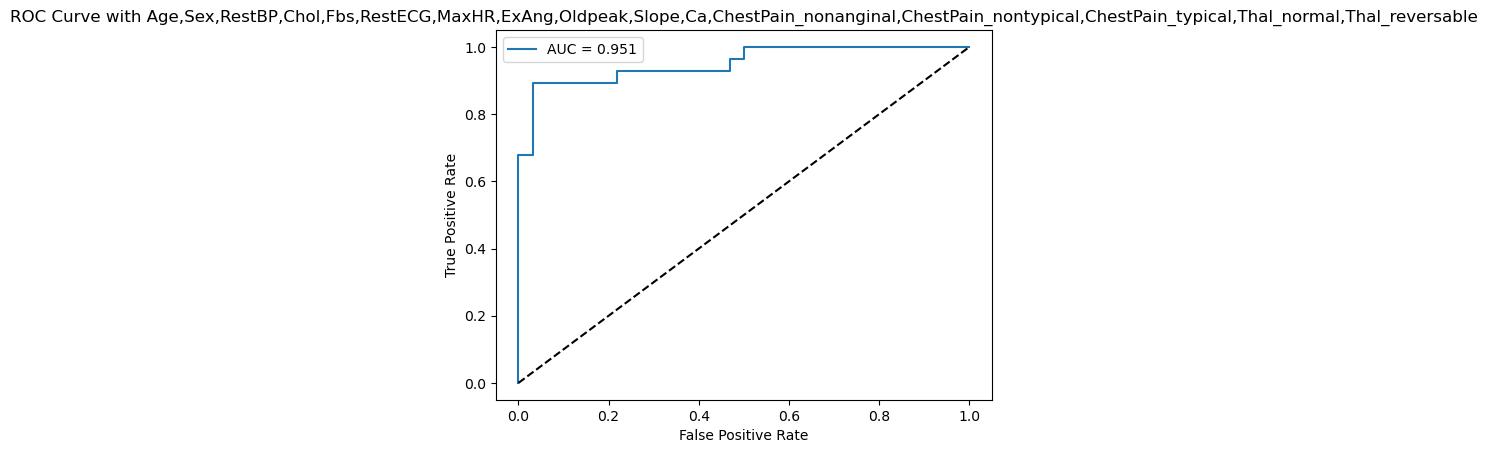

In [48]:
from sklearn.metrics import roc_auc_score,roc_curve
import matplotlib.pyplot as plt
X = df[predictors[2]]  # all predictors
    
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=777
)

model = LogisticRegression(max_iter=2000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
fpr, tpr, thresholds = roc_curve(y_test, model.predict_proba(X_test)[:,1])
auc = roc_auc_score(y_test, model.predict_proba(X_test)[:,1])
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f"ROC Curve with {','.join(predictors[2] )  }")
plt.legend()
plt.show()